# Global Power Plant Database
provided by the World Resources Institute, contains detailed information about power plants worldwide.

**Objective**: Utilize advanced statistical functions and array operations in NumPy, and integrate these with Pandas for data manipulation and Matplotlib for visualization.

The database covers approximately 30,000 power plants from 164 countries and includes thermal plants (e.g., coal, gas, oil, nuclear, biomass, waste, geothermal) and renewables (e.g., hydro, wind, solar). Each power plant is geolocated, and entries contain information on plant capacity, generation, ownership, and fuel type.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

**1. Data Import and Cleaning:**

Import the dataset using Pandas.
Identify missing values and handle them appropriately.
Use NumPy to convert relevant columns to numerical types if necessary.

In [2]:
df = pd.read_csv('/content/sample_data/global_power_plant_database.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34936 entries, 0 to 34935
Data columns (total 36 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   country                         34936 non-null  object 
 1   country_long                    34936 non-null  object 
 2   name                            34936 non-null  object 
 3   gppd_idnr                       34936 non-null  object 
 4   capacity_mw                     34936 non-null  float64
 5   latitude                        34936 non-null  float64
 6   longitude                       34936 non-null  float64
 7   primary_fuel                    34936 non-null  object 
 8   other_fuel1                     1944 non-null   object 
 9   other_fuel2                     276 non-null    object 
 10  other_fuel3                     92 non-null     object 
 11  commissioning_year              17447 non-null  float64
 12  owner                           

/tmp/ipykernel_1050/4178421278.py:1: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/sample_data/global_power_plant_database.csv')


In [4]:
# check for duplicates
df.duplicated().sum()

np.int64(0)

In [42]:
print(df.head(5))
print(df['generation_data_source'].unique())

  country country_long                                              name  \
0     AFG  Afghanistan      Kajaki Hydroelectric Power Plant Afghanistan   
1     AFG  Afghanistan                                      Kandahar DOG   
2     AFG  Afghanistan                                      Kandahar JOL   
3     AFG  Afghanistan     Mahipar Hydroelectric Power Plant Afghanistan   
4     AFG  Afghanistan  Naghlu Dam Hydroelectric Power Plant Afghanistan   

      gppd_idnr  capacity_mw  latitude  longitude primary_fuel other_fuel1  \
0  GEODB0040538         33.0    32.322    65.1190        Hydro         NaN   
1    WKS0070144         10.0    31.670    65.7950        Solar         NaN   
2    WKS0071196         10.0    31.623    65.7920        Solar         NaN   
3  GEODB0040541         66.0    34.556    69.4787        Hydro         NaN   
4  GEODB0040534        100.0    34.641    69.7170        Hydro         NaN   

  other_fuel2  ... estimated_generation_gwh_2014  \
0         NaN  ...    

**2. Exploratory Data Analysis:**

Utilize Pandas to summarize key statistics (mean, median, standard deviation) for numerical columns.
Explore the distribution of power plants by country and fuel type.

In [7]:
df.describe()

,capacity_mw,latitude,longitude,commissioning_year,year_of_capacity_data,generation_gwh_2013,generation_gwh_2014,generation_gwh_2015,generation_gwh_2016,generation_gwh_2017,generation_gwh_2018,generation_gwh_2019,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017
count,34936.000000,34936.000000,34936.000000,17447.000000,14887.000000,6417.000000,7226.000000,8203.000000,9144.000000,9500.000000,9637.000000,9659.000000,16120.000000,16503.000000,17050.000000,17570.000000,33138.000000
mean,163.355148,32.816637,-6.972803,1997.414823,2018.218849,592.696107,656.863891,762.368840,693.149763,661.834161,517.320785,423.922436,239.112221,242.431122,235.866067,235.695265,716.443378
std,489.636072,22.638603,78.405850,23.397835,1.606428,2174.833482,2231.464288,2533.459828,2404.516759,2369.296957,1975.302686,1698.506485,1191.258172,1285.798297,1267.005223,1259.559841,2484.361200
min,1.000000,-77.847000,-179.977700,1896.000000,2000.000000,-947.600000,-989.619000,-864.428000,-768.620000,-934.944000,-982.622000,-780.339000,1.120000,0.870000,0.440000,0.300000,0.000000
25%,4.900000,29.256475,-77.641550,1988.000000,2017.000000,1.947000,2.260000,2.664500,2.729000,2.467000,2.242000,2.751500,8.620000,8.680000,8.380000,8.322500,8.180000
50%,16.745000,39.727750,-2.127100,2007.000000,2019.000000,23.426000,23.608500,26.142000,22.462389,17.876500,12.530000,11.530000,27.620000,28.250000,26.830000,27.555000,37.590000
75%,75.344250,46.263125,49.502675,2014.000000,2019.000000,199.706000,226.322250,285.862583,249.866750,214.505150,151.117000,122.781498,106.805000,106.980000,103.120000,107.237500,229.565000
max,22500.000000,71.292000,179.388700,2020.000000,2019.000000,50834.000000,32320.917000,37433.607000,32377.477000,36448.643000,35136.000000,31920.368000,48675.060000,58470.770000,57113.350000,60859.730000,82810.770000


In [10]:
# count power plans by country
df['country_long'].value_counts()

,count
country_long,
United States of America,9833
China,4235
United Kingdom,2751
Brazil,2360
France,2155
...,...
Guinea-Bissau,1
Saint Lucia,1
Palestine,1


In [13]:
len(df['country_long'].unique())

167

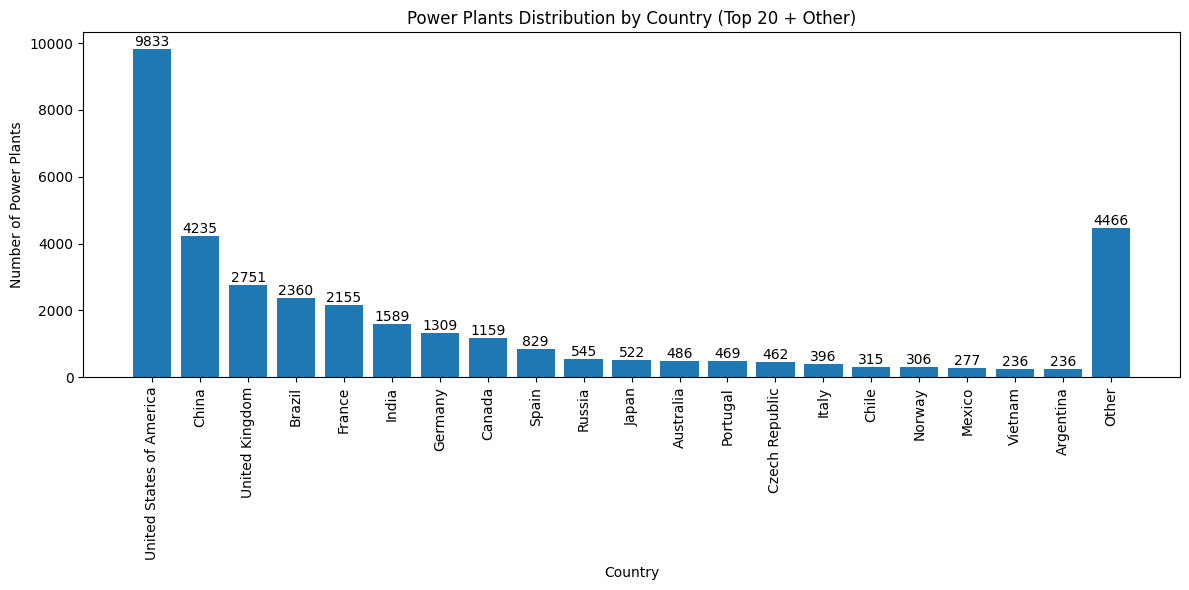

In [31]:
# plot a bar chart of top 20 countries + other
top_n = 20
country_counts = df['country_long'].value_counts()

top_n_countries = country_counts.head(top_n).reset_index()
top_n_countries.columns = ['country', 'count']

other_countries_sum = country_counts.iloc[top_n:].sum()
other_df = pd.DataFrame([{'country': 'Other', 'count': other_countries_sum}])

# Combine top countries and 'Other'
combined_df = pd.concat([top_n_countries, other_df], ignore_index=True)

# Plotting
plt.figure(figsize=(12, 6))
plt.bar(combined_df['country'], combined_df['count'])
plt.xticks(rotation=90)
plt.title('Power Plants Distribution by Country (Top 20 + Other)')
plt.ylabel('Number of Power Plants')
plt.xlabel('Country')
plt.bar_label(plt.gca().containers[0])
plt.tight_layout()
plt.show()

Power plant counts by primary fuel type:
primary_fuel
Solar             10665
Hydro              7156
Wind               5344
Gas                3998
Coal               2330
Oil                2320
Biomass            1430
Waste              1068
Nuclear             195
Geothermal          189
Storage             135
Other                43
Cogeneration         41
Petcoke              12
Wave and Tidal       10
Name: count, dtype: int64


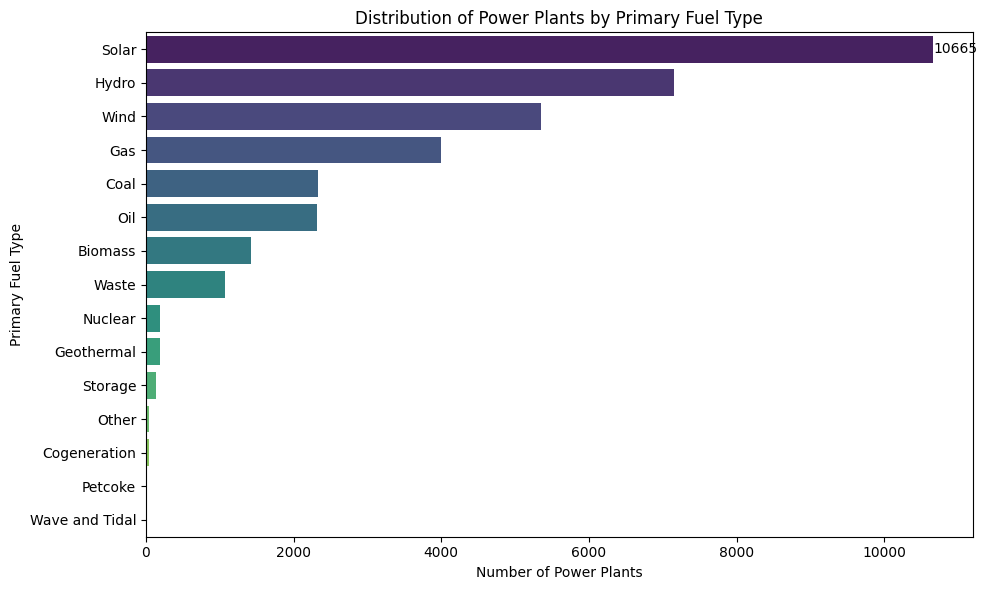

In [37]:
# Analyze the distribution of power plants by primary fuel type
fuel_counts = df['primary_fuel'].value_counts()

# Display the counts
print("Power plant counts by primary fuel type:")
print(fuel_counts)

# Visualize the distribution using a pie chart or horizontal bar chart
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=fuel_counts.values, y=fuel_counts.index, hue=fuel_counts.index, palette='viridis', legend=False)
plt.title('Distribution of Power Plants by Primary Fuel Type')
plt.xlabel('Number of Power Plants')
plt.ylabel('Primary Fuel Type')
plt.tight_layout()
plt.show()

**3. Statistical Analysis:**

Perform a statistical analysis of power output by fuel type using NumPy’s statistical functions.
Use hypothesis testing to determine if the mean power output differs significantly between different fuel types.

In [82]:
#avg_annual_gwh
df['avg_annual_gwh'] = df[['generation_gwh_2013','generation_gwh_2014','generation_gwh_2015','generation_gwh_2016','generation_gwh_2017','generation_gwh_2018','generation_gwh_2019']].mean(axis=1)

# count and average output by fueld type
fuel_output = df.groupby('primary_fuel')['avg_annual_gwh'].agg(['count', 'min','max','mean','median','std']).reset_index()
fuel_output.columns = ['fuel_type', 'count','min','max', 'mean','median','std']

# reviewing the basis statistics on each fuel type:
fuel_output

,fuel_type,count,min,max,mean,median,std
0,Biomass,179,-0.364667,1895.064000,189.841546,31.572833,296.007524
1,Coal,646,0.000000,31850.220333,3918.569260,2548.534833,4592.207766
2,Cogeneration,34,0.000000,526.065309,98.635829,39.131929,135.495518
3,Gas,2196,-91.389793,20570.175818,812.035839,101.432857,1577.215812
4,Geothermal,68,0.444286,4604.311571,250.878311,134.519000,559.099033
5,Hydro,2050,-895.453143,50834.000000,347.158014,52.382414,1550.996072
6,Nuclear,115,0.000000,34670.114000,13512.312633,13408.495000,6965.837144
7,Oil,920,-29.428714,13636.874398,53.238017,0.107058,536.467958
8,Other,20,0.459333,845.784667,141.331576,53.715091,223.893958
9,Petcoke,11,0.089794,6162.181699,714.244107,32.627426,1825.531410


In [91]:
df[(df['primary_fuel'] == 'Storage') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh']

,avg_annual_gwh
24771,-0.080500
24774,-0.588000
24775,-0.007000
24777,-0.081750
24779,-1.560000
...,...
33845,-2.322000
33949,576.592851
34212,3.159000
34315,-1.394750


In [105]:
import scipy.stats as stats
#comparing average annual generation by fuel type overall via ANOVA:

f_stat, p_value = stats.f_oneway(
    df[(df['primary_fuel'] == 'Hydro') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Biomass') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Geothermal') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Other') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Solar') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Waste') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Wind') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    # df[(df['primary_fuel'] == 'Wave and Tidal') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Oil') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Gas') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Coal') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Nuclear') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Storage') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Cogeneration') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Petcoke') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh']
)



#    df[df['avg_annual_gwh'].isnull() == False][['generation_gwh_2013','generation_gwh_2014','generation_gwh_2015','generation_gwh_2016','generation_gwh_2017','generation_gwh_2018','generation_gwh_2019']])
print("ANOVA:\n")
print(f"F-Statistic: {f_stat}")
print(f"p-value: {p_value}")
if p_value < 0.01:
  print("The means of the groups are significantly different.\n")
else:
  print("The means of the groups are not significantly different.\n")

# Now ANOVA only on large sample fuel type of similar sample size: Gas, Hydro, Wind, Solar:

f_stat, p_value = stats.f_oneway(
    df[(df['primary_fuel'] == 'Hydro') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Solar') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Wind') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
    df[(df['primary_fuel'] == 'Gas') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh']
)



#    df[df['avg_annual_gwh'].isnull() == False][['generation_gwh_2013','generation_gwh_2014','generation_gwh_2015','generation_gwh_2016','generation_gwh_2017','generation_gwh_2018','generation_gwh_2019']])
print("ANOVA:\n")
print(f"F-Statistic: {f_stat}")
print(f"p-value: {p_value}")
if p_value < 0.01:
  print("The means of the groups are significantly different.\n")
else:
  print("The means of the groups are not significantly different.\n")



# sample size of Wind is significanlty smaller than Hydro and Solar. Hence t test and not Anova analysis

# T-test between Hydro and Solar
print("T-test between Hydro and Solar")
t_test, p_val = stats.ttest_ind(df[(df['primary_fuel'] == 'Hydro') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
                                df[(df['primary_fuel'] == 'Solar') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'])

print(f"T-test: {t_test}, p-value: {p_val}")
if p_val < 0.05:
    print("The difference in means is statistically significant.\n")
else:
    print("The difference in means is not statistically significant.\n")

# T-test between Hydro and Wind
print("T-test between Hydro and Wind")
t_test, p_val = stats.ttest_ind(df[(df['primary_fuel'] == 'Hydro') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'],
                                df[(df['primary_fuel'] == 'Wind') & (df['avg_annual_gwh'].isnull() == False)]['avg_annual_gwh'])

print(f"T-test: {t_test}, p-value: {p_val}")
if p_val < 0.05:
    print("The difference in means is statistically significant.\n")
else:
    print("The difference in means is not statistically significant.\n")


ANOVA:

F-Statistic: 824.8742096360766
p-value: 0.0
The means of the groups are significantly different.

ANOVA:

F-Statistic: 231.44164289623373
p-value: 1.6828075571790503e-144
The means of the groups are significantly different.

T-test between Hydro and Solar
T-test: 12.083047574597161, p-value: 3.511280318164844e-33
The difference in means is statistically significant.

T-test between Hydro and Wind
T-test: 2.11807488785696, p-value: 0.03424417885687994
The difference in means is statistically significant.



**4. Time Series Analysis:**

If the dataset includes time-related data (like year of establishment), use NumPy to analyze trends over time.
Explore how the mix of fuel types for power generation has evolved over the years.

--- Task 4: Time Series Analysis ---
    commissioning_year decade
9               1965.0   1960
10              1978.0   1970
11              1985.0   1980
primary_fuel  Biomass  Coal  Cogeneration  Gas  Geothermal  Hydro  Nuclear  \
decade                                                                       
1930                0     7             0   20           0    147        0   
1940                1    13             0   24           0    199        0   
1950                5    49             2   77           0    405        0   
1960               21   107             1  151           3    405        2   
1970               31   182             3  225           7    275       34   
1980               53   212             7  295          30    551       49   
1990               64   249             8  533          44    348        5   
2000              254   596             8  889          31    526        4   
2010              152   475             5  522          28    4

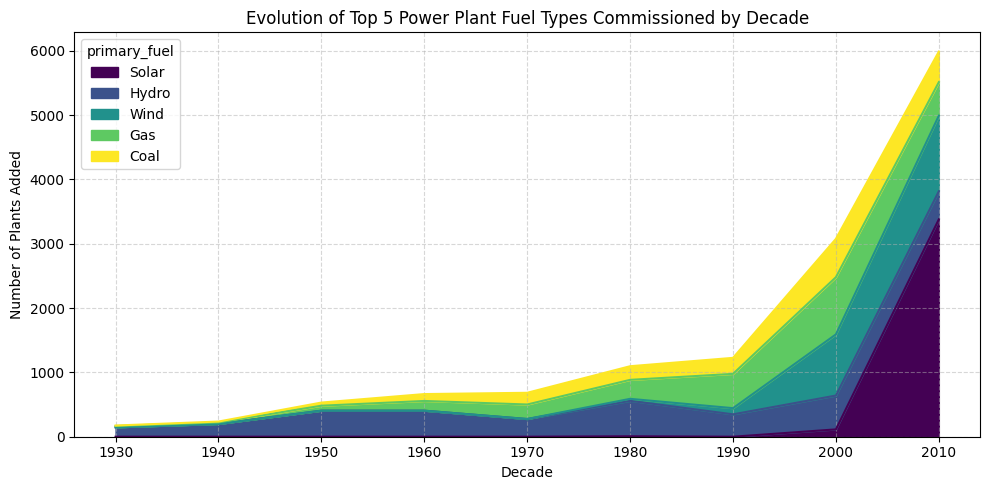

In [110]:
# ========================================================
# **Task 4: Time Series Analysis (Evolution of Fuel Mix)**
# ========================================================

print("--- Task 4: Time Series Analysis ---")
# Filter out missing commissioning years and bin years by decades using NumPy
time_df = df[df['commissioning_year'].notnull()].copy()
decade_bins = np.arange(1930, 2030, 10)
time_df['decade'] = pd.cut(time_df['commissioning_year'], bins=decade_bins, labels=decade_bins[:-1])

print(time_df[['commissioning_year','decade']].head(3))

# Count dominant fuel types added over each decade
decade_fuel = time_df.groupby(['decade', 'primary_fuel'], observed=False).size().unstack(fill_value=0)
print(decade_fuel)
top_fuels = df['primary_fuel'].value_counts().head(5).index
decade_fuel_top = decade_fuel[top_fuels]
print(decade_fuel_top)

plt.figure(figsize=(10, 5))
decade_fuel_top.plot(kind='area', stacked=True, colormap='viridis', figsize=(10, 5), ax=plt.gca())
plt.title('Evolution of Top 5 Power Plant Fuel Types Commissioned by Decade')
plt.ylabel('Number of Plants Added')
plt.xlabel('Decade')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**5. Advanced Visualization:**

Create visualizations using Matplotlib and Seaborn to illustrate your findings.
Consider plotting the geographical distribution of power plants using latitude and longitude data, if available.


--- Task 5: Advanced Visualization ---


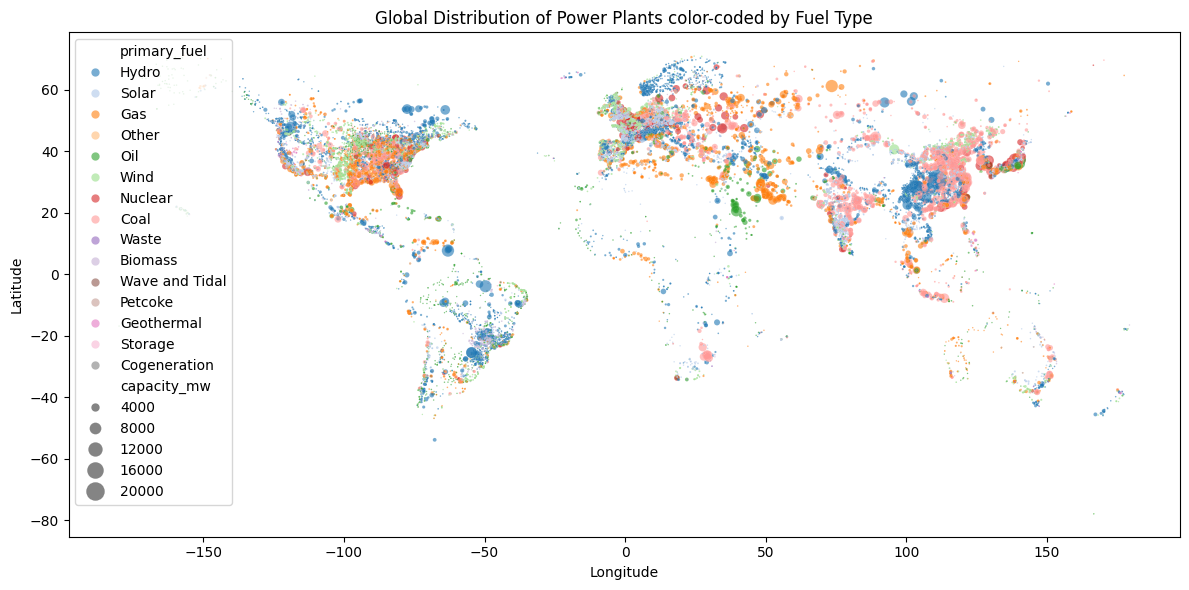

In [112]:
# ========================================================
# **Task 5: Advanced Visualization (Geographical Scatter)**
# ========================================================

print("\n--- Task 5: Advanced Visualization ---")
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df,
    x='longitude',
    y='latitude',
    hue='primary_fuel',
    palette='tab20',
    size='capacity_mw',
    sizes=(1, 200),
    alpha=0.6
)
plt.title('Global Distribution of Power Plants color-coded by Fuel Type')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(loc='upper left', ncol=1)
plt.tight_layout()
plt.show()



**6. Matrix Operations in Real-World Context:**

Demonstrate matrix operations by analyzing relationships between different attributes (e.g., fuel type, capacity, and geographic location).
Discuss the relevance of eigenvectors and eigenvalues in this context.

In [113]:


# ========================================================
# **Task 6: Matrix Operations (Covariance & Eigenvalues)**
# ========================================================
print("\n--- Task 6: Matrix Operations ---")
# Drop NaNs for the numerical columns of interest
matrix_data = df[['capacity_mw', 'latitude', 'longitude', 'commissioning_year']].dropna()

# Convert to a NumPy matrix and standardize the data column-wise
X = matrix_data.values
# subtract from each column the rows mean and divide each column by row-stddev in that column:
X_standardized = (X - np.mean(X, axis=0)) / np.std(X, axis=0)

# Compute the Covariance Matrix using NumPy's matrix multiplication
n_samples = X_standardized.shape[0]
covariance_matrix = (X_standardized.T @ X_standardized) / (n_samples - 1)

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(covariance_matrix)

print("Standardized Attributes: ['capacity_mw', 'latitude', 'longitude', 'commissioning_year']")
print("\nCovariance Matrix:\n", covariance_matrix)
print("\nEigenvalues (Variance Explained):\n", eigenvalues)
print("\nEigenvectors (Principal Directions):\n", eigenvectors)


--- Task 6: Matrix Operations ---
Standardized Attributes: ['capacity_mw', 'latitude', 'longitude', 'commissioning_year']

Covariance Matrix:
 [[ 1.00005732  0.00914496  0.3398044  -0.01390775]
 [ 0.00914496  1.00005732 -0.10310041 -0.15221651]
 [ 0.3398044  -0.10310041  1.00005732 -0.02369508]
 [-0.01390775 -0.15221651 -0.02369508  1.00005732]]

Eigenvalues (Variance Explained):
 [0.63681956 1.35273361 0.85729719 1.15337892]

Eigenvectors (Principal Directions):
 [[-0.6523787   0.67787111  0.29104532 -0.17373951]
 [ 0.26977388 -0.19371531  0.64508109 -0.68816191]
 [ 0.69556908  0.70914027 -0.11107886 -0.03106801]
 [ 0.13344562  0.0092319   0.69772809  0.70376313]]


### 🧠 What do Eigenvalues and Eigenvectors mean in this context?

In Task 6, we standardized four major attributes of the power plants:
1. **Capacity (MW)**
2. **Latitude**
3. **Longitude**
4. **Commissioning Year**

By calculating the covariance matrix and finding its eigenvalues and eigenvectors, we are performing the core mathematical step of **Principal Component Analysis (PCA)**. Here is how to interpret the output:

#### 1. Eigenvectors (Principal Directions / Axes of Variation)
Each eigenvector represents a **new, composite direction (axis)** in our 4-dimensional space that combines our original variables.
* Looking at the eigenvectors matrix, each column is a vector. For example, if a column has high weights for both `latitude` and `longitude`, it represents a geographic direction/axis.
* If a column has high values for both `capacity_mw` and `commissioning_year`, it represents an axis showing how capacity changes over time (e.g., size progression trend).

#### 2. Eigenvalues (Amount of Variance Explained)
Eigenvalues tell us **how much information (variance)** is captured along each corresponding eigenvector's direction.
* In our standardized dataset, each of our 4 original variables has a variance of exactly `1.0` (total variance = `4.0`).
* The calculated eigenvalues are: **`[0.637, 1.353, 0.857, 1.153]`**.
* The eigenvalue of **`1.353`** is the largest. This means its corresponding eigenvector (the second principal axis) is the most dominant pattern/trend in our data, capturing more information than any single original variable alone.
* The eigenvalue of **`0.637`** is the smallest, meaning that direction contains the least amount of distinct pattern or variation.



**7. Integrating NumPy with Pandas and Matplotlib:**

Show how NumPy can be used to enhance data manipulation in Pandas and data visualization in Matplotlib.
Provide examples, such as using NumPy arrays for complex filtering in Pandas or for creating sophisticated plots in Matplotlib.


--- Task 7: Integrating NumPy, Pandas & Matplotlib ---
Found 81 high-capacity, high-generation Hydro power plants using NumPy filtering.


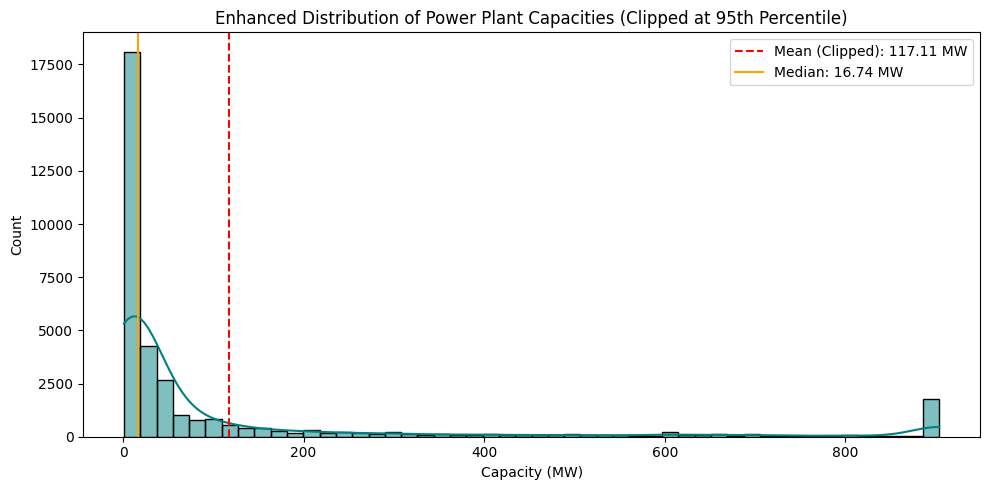

In [114]:
# ========================================================
# **Task 7: Integrating NumPy with Pandas and Matplotlib**
# ========================================================
print("\n--- Task 7: Integrating NumPy, Pandas & Matplotlib ---")
# Using NumPy's percentile and clipping to remove extreme outliers for visualization
capacity_array = df['capacity_mw'].to_numpy()
p95 = np.percentile(capacity_array, 95)

# Enhance Pandas filtering using a complex NumPy condition
high_efficiency_hydro_idx = np.where(
    (df['primary_fuel'].to_numpy() == 'Hydro') &
    (df['capacity_mw'].to_numpy() > 500) &
    (df['avg_annual_gwh'].to_numpy() > 1000)
)[0]

hydro_subset = df.iloc[high_efficiency_hydro_idx]
print(f"Found {len(hydro_subset)} high-capacity, high-generation Hydro power plants using NumPy filtering.")

# Sophisticated clipped capacity distribution plot
clipped_capacity = np.clip(capacity_array, a_min=None, a_max=p95)
plt.figure(figsize=(10, 5))
sns.histplot(clipped_capacity, bins=50, kde=True, color='teal')
plt.axvline(np.mean(clipped_capacity), color='red', linestyle='--', label=f'Mean (Clipped): {np.mean(clipped_capacity):.2f} MW')
plt.axvline(np.median(clipped_capacity), color='orange', linestyle='-', label=f'Median: {np.median(clipped_capacity):.2f} MW')
plt.title('Enhanced Distribution of Power Plant Capacities (Clipped at 95th Percentile)')
plt.xlabel('Capacity (MW)')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()